# **☘ Beauty & Wellness E-Commerce Analytics: Customer Behavior and Product Performance Analysis**

##**Import Libraries**

In [30]:
# Import pandas for data manipulation
import pandas as pd

# Import numpy for scientific computing
import numpy as np

# Import seaborn for statistical data visualization
import seaborn as sns

# Import matplotlib for custom plots and layouts
import matplotlib.pyplot as plt

# Import MinMaxScaler to scale features between 0 and 1
from sklearn.preprocessing import MinMaxScaler

##**Merge Mutiple Dataset**

In [31]:
# Load December transaction records
df1 = pd.read_csv('Dec.csv')

# Load February transaction records
df2 = pd.read_csv('Feb.csv')

# Load January transaction records
df3 = pd.read_csv('Jan.csv')

# Load November transaction records
df4 = pd.read_csv('Nov.csv')

# Load October transaction records
df5 = pd.read_csv('Oct.csv')

# Combine all loaded dataframes into a single dataframe
final_df = pd.concat([df1, df2, df3, df4, df5], ignore_index=True)

# Drop identical duplicate rows
final_df = final_df.drop_duplicates()

# Export the combined data to a CSV file
final_df.to_csv('Final_Combined_Dataset.csv', index=False)

##**Display First And Last Five Records**

In [32]:
# Print text header
print("\nFirst 5 Records:")

# Retrieve and display the first 5 records
final_df.head()


First 5 Records:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-12-01 00:00:00 UTC,remove_from_cart,5712790.0,1.487580e+18,NaN,f.o.x,6.27,576802932.0,51d85cb0-897f-48d2-918b-ad63965c12dc
1,2019-12-01 00:00:00 UTC,view,5764655.0,1.487580e+18,NaN,cnd,29.05,412120092.0,8adff31e-2051-4894-9758-224bfa8aec18
2,2019-12-01 00:00:02 UTC,cart,4958.0,1.487580e+18,NaN,runail,1.19,494077766.0,c99a50e8-2fac-4c4d-89ec-41c05f114554
3,2019-12-01 00:00:05 UTC,view,5848413.0,1.487580e+18,NaN,freedecor,0.79,348405118.0,722ffea5-73c0-4924-8e8f-371ff8031af4
4,2019-12-01 00:00:07 UTC,view,5824148.0,1.487580e+18,NaN,NaN,5.56,576005683.0,28172809-7e4a-45ce-bab0-5efa90117cd5


In [33]:
# Print text header
print("\nLast 5 Records:")

# Retrieve and display the last 5 records
final_df.tail()


Last 5 Records:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
1310717,2019-10-02 11:36:03 UTC,cart,5876948.0,1.487580e+18,NaN,dizao,1.57,555992489.0,7003dba4-88f7-4bd9-a61b-5e34435fa6f7
1310718,2019-10-02 11:36:03 UTC,remove_from_cart,5873241.0,1.487580e+18,NaN,lianail,6.33,200698039.0,359ea082-0dba-43d2-9b68-aa0a15be20db
1310719,2019-10-02 11:36:03 UTC,view,5846096.0,1.487580e+18,NaN,NaN,52.22,555992619.0,36f07a64-bdc2-4fd5-a778-e6f33e20fd71
1310721,2019-10-02 11:36:03 UTC,view,5689212.0,1.487580e+18,NaN,dizao,1.67,555992604.0,92093496-6650-46fe-9703-c72066393106
1310732,2019-10-02 11:36:03 UTC,remove_from_cart,5873241.0,1.487580e+12,NaN,NaN,NaN,NaN,NaN


##**Display Total Columns And Rows**

In [34]:
# Print text header
print("\nTotal Rows and Columns:")

# Display structural dimensions of the dataframe
print(final_df.shape)


Total Rows and Columns:
(1236533, 9)


##**Dataset Information**

In [35]:
# Print text header
print("Dataset Information:")

# Generate structural information of columns and data types
final_df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 1236533 entries, 0 to 1310732
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype  
---  ------         --------------    -----  
 0   event_time     1236533 non-null  object 
 1   event_type     1236531 non-null  object 
 2   product_id     1236531 non-null  float64
 3   category_id    1236531 non-null  float64
 4   category_code  20567 non-null    object 
 5   brand          719534 non-null   object 
 6   price          1236529 non-null  float64
 7   user_id        1236529 non-null  float64
 8   user_session   1236248 non-null  object 
dtypes: float64(4), object(5)
memory usage: 94.3+ MB


##**Dataset Description**

In [36]:
# Print text header
print("\nDataset Description:")

# Calculate basic statistics of numerical attributes
final_df.describe()


Dataset Description:


,product_id,category_id,price,user_id
count,1.236531e+06,1.236531e+06,1.236529e+06,1.236529e+06
mean,5.484764e+06,1.558657e+18,8.931108e+00,5.198421e+08
std,1.305405e+06,1.750321e+17,2.017926e+01,8.619532e+07
min,3.752000e+03,1.487580e+05,-4.762000e+01,6.095000e+03
25%,5.726164e+06,1.487580e+18,2.140000e+00,4.840253e+08
50%,5.810721e+06,1.487580e+18,4.060000e+00,5.531882e+08
75%,5.857280e+06,1.487580e+18,7.140000e+00,5.770740e+08
max,5.924514e+06,2.235524e+18,3.277800e+02,6.095899e+08


##**Handling Missing**

In [37]:
# Calculate and display the count of missing values per column
final_df.isnull().sum()

,0
event_time,0
event_type,2
product_id,2
category_id,2
category_code,1215966
brand,516999
price,4
user_id,4
user_session,285


In [38]:
# Fill missing values in brand column with unknown
final_df['brand'] = final_df['brand'].fillna('Unknown')

# Fill missing values in category code with unknown
final_df['category_code'] = final_df['category_code'].fillna('Unknown')

# Fill missing values in user session with unknown
final_df['user_session'] = final_df['user_session'].fillna('Unknown')

# Fill missing values in event type with unknown
final_df['event_type'] = final_df['event_type'].fillna('Unknown')

# Replace missing price records with median values
final_df['price'] = final_df['price'].fillna(final_df['price'].median())

# Fill missing user id identifiers with negative one
final_df['user_id'] = final_df['user_id'].fillna(-1)

# Fill missing category identifiers with negative one
final_df['category_id'] = final_df['category_id'].fillna(-1)

# Fill missing product identifiers with negative one
final_df['product_id'] = final_df['product_id'].fillna(-1)

# Convert date field to standard UTC timestamp
final_df['event_time'] = pd.to_datetime(final_df['event_time'], errors='coerce', utc=True)

# Calculate the median date timestamp
median_time = final_df['event_time'].dropna().median()

# Impute missing date fields with median timestamp
final_df['event_time'] = final_df['event_time'].fillna(median_time)

# Display computed median timestamp
print("Median Time:", median_time)

# Display quantity of null date timestamps
print("Missing Values:", final_df['event_time'].isnull().sum())

# Sum up remaining missing values across all columns
final_df.isnull().sum()

Median Time: 2019-12-02 12:10:08+00:00
Missing Values: 0


,0
event_time,0
event_type,0
product_id,0
category_id,0
category_code,0
brand,0
price,0
user_id,0
user_session,0


##**Remove Duplicate Records**

In [39]:
# Print text header
print("Duplicates Before:")

# Display quantity of duplicate rows
final_df.duplicated().sum()

Duplicates Before:


np.int64(1)

In [40]:
# Remove duplicate rows in-place
final_df = final_df.drop_duplicates()

# Print text header
print("Duplicates After:")

# Check and display count of remaining duplicates
final_df.duplicated().sum()

Duplicates After:


np.int64(0)

##**Handle Data Inconsistencies**

In [41]:
# Clean and cast event types to lower case strings
final_df['event_type'] = final_df['event_type'].astype(str).str.lower().str.strip()

# Clean and cast brand names to lower case strings
final_df['brand'] = final_df['brand'].astype(str).str.lower().str.strip()

# Clean and cast category descriptions to lower case strings
final_df['category_code'] = final_df['category_code'].astype(str).str.lower().str.strip()

# Convert event dates into standardized datetime object type
final_df['event_time'] = pd.to_datetime(final_df['event_time'], errors='coerce')

# Coerce price inputs into float types safely
final_df['price'] = pd.to_numeric(final_df['price'], errors='coerce')

# Drop records with invalid or absent values in price column
final_df = final_df.dropna(subset=['price'])

# Filter out items with negative or zero price configurations
final_df = final_df[final_df['price'] > 0]

# Print status confirming inconsistencies have been resolved
print("Data Inconsistencies Handled!")

Data Inconsistencies Handled!


##**Detect Outliers**

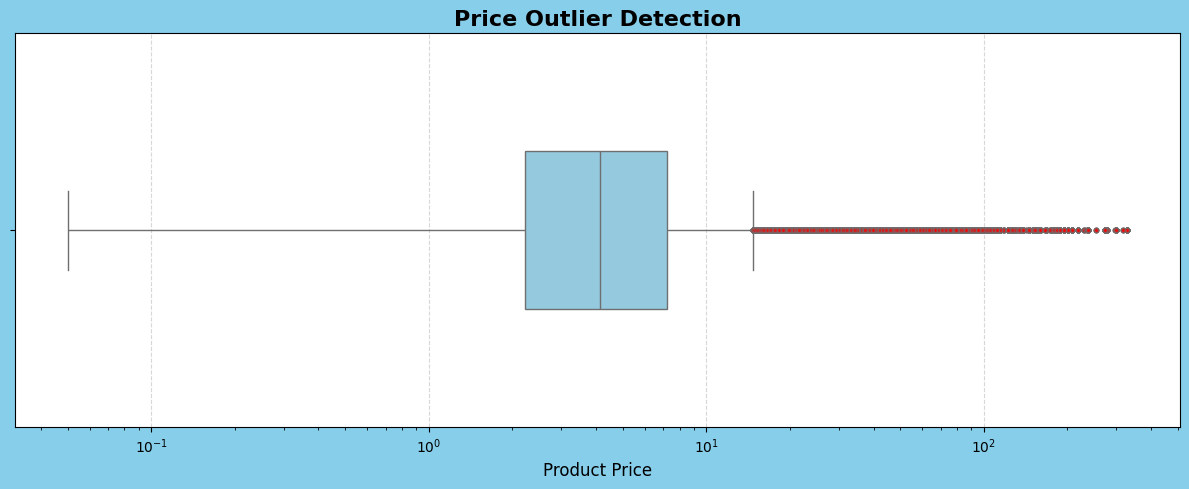

In [42]:
# Import library for charting
import matplotlib.pyplot as plt

# Import library for advanced visualizations
import seaborn as sns

# Configure graphic size and background canvas color
plt.figure(figsize=(12, 5), facecolor="skyblue")

# Draw a horizontal boxplot diagram to highlight price distribution anomalies
sns.boxplot(
    x=final_df['price'],
    color='skyblue',
    width=0.4,
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'red',
        'markersize': 3,
        'alpha': 0.4
    }
)

# Assign descriptive titles with formatting attributes
plt.title('Price Outlier Detection', fontsize=16, fontweight='bold')

# Specify label string for horizontal axis
plt.xlabel('Product Price', fontsize=12)

# Apply scale transform on price value axis
plt.xscale('log')

# Draw vertical reference lines
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Clean up plot padding configurations
plt.tight_layout()

# Display constructed graphic
plt.show()

##**Handle Outliers Using IQR**

In [43]:
# Determine lower quartile value
Q1 = final_df['price'].quantile(0.25)

# Determine upper quartile value
Q3 = final_df['price'].quantile(0.75)

# Compute dynamic interquartile range margin
IQR = Q3 - Q1

# Compute lower bounding limit threshold
lower = Q1 - 1.5 * IQR

# Compute upper bounding limit threshold
upper = Q3 + 1.5 * IQR

# Truncate values staying outside calculated boundaries
final_df['price'] = final_df['price'].clip(lower, upper)

# Confirm completion of cap clipping
print("Outliers Handled!")

Outliers Handled!


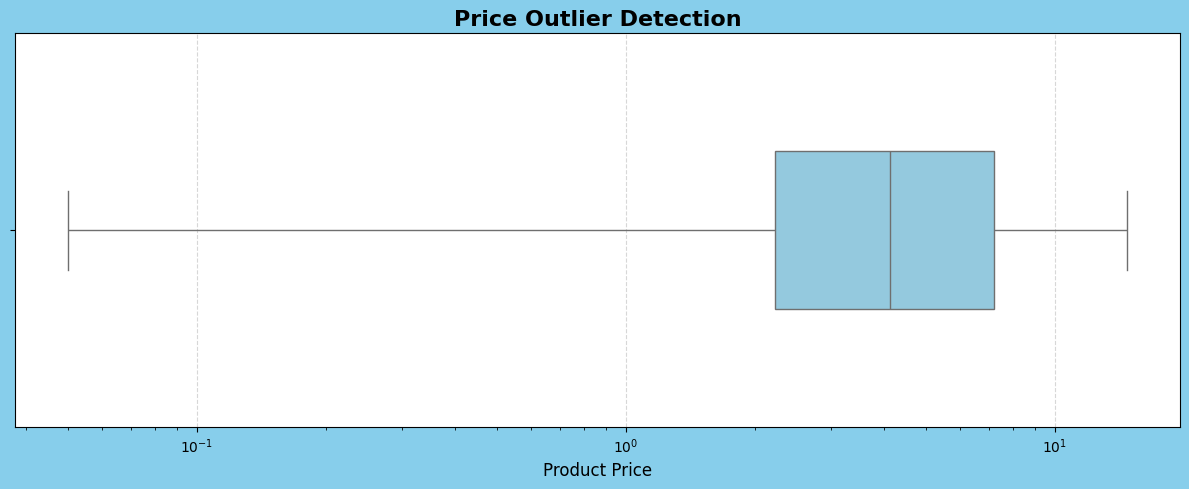

In [44]:
# Import visual modeling tools
import matplotlib.pyplot as plt

# Import statistical data presentation structures
import seaborn as sns

# Create a visualization layer with background color themes
plt.figure(figsize=(12, 5), facecolor="skyblue")

# Generate a boxplot on the clipped price values
sns.boxplot(
    x=final_df['price'],
    color='skyblue',
    width=0.4,
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'red',
        'markersize': 3,
        'alpha': 0.4
    }
)

# Apply visual title descriptors
plt.title('Price Outlier Detection', fontsize=16, fontweight='bold')

# Apply custom label on X-axis
plt.xlabel('Product Price', fontsize=12)

# Use logarithmic scaling parameters
plt.xscale('log')

# Render grid lines on specific metrics
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Adapt padding for aesthetic output
plt.tight_layout()

# Display resulting boxplot graph
plt.show()

##**Normalization**

In [45]:
# Instantiate scaling model instance
scaler = MinMaxScaler()

# Compute scales and normalize original product prices
final_df['price_normalized'] = scaler.fit_transform(final_df[['price']])

# Inspect and display sample transformation results
print(final_df[['price', 'price_normalized']].head())

   price  price_normalized
0   6.27          0.423995
1  14.72          1.000000
2   1.19          0.077710
3   0.79          0.050443
4   5.56          0.375596


##**Check Cleaned Dataset**

In [46]:
# Print summary details text
print("Cleaned Dataset Information:")

# View variable parameters, count records, and examine type features
final_df.info()

# Print missing records header
print("\nMissing Values:")

# Check for any remaining null inputs
final_df.isnull().sum()

# Print final dataset shape header
print("\nFinal Dataset Shape:")

# Display spatial characteristics of the final dataframe
final_df.shape

# Print clean dataset records header
print("\nCleaned Dataset:")

# Return top records to check cleanliness
final_df.head()

Cleaned Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 1223505 entries, 0 to 1310732
Data columns (total 10 columns):
 #   Column            Non-Null Count    Dtype              
---  ------            --------------    -----              
 0   event_time        1223505 non-null  datetime64[ns, UTC]
 1   event_type        1223505 non-null  object             
 2   product_id        1223505 non-null  float64            
 3   category_id       1223505 non-null  float64            
 4   category_code     1223505 non-null  object             
 5   brand             1223505 non-null  object             
 6   price             1223505 non-null  float64            
 7   user_id           1223505 non-null  float64            
 8   user_session      1223505 non-null  object             
 9   price_normalized  1223505 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(5), object(4)
memory usage: 102.7+ MB

Missing Values:

Final Dataset Shape:

Cleaned Datas

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,price_normalized
0,2019-12-01 00:00:00+00:00,remove_from_cart,5712790.0,1.487580e+18,unknown,f.o.x,6.27,576802932.0,51d85cb0-897f-48d2-918b-ad63965c12dc,0.423995
1,2019-12-01 00:00:00+00:00,view,5764655.0,1.487580e+18,unknown,cnd,14.72,412120092.0,8adff31e-2051-4894-9758-224bfa8aec18,1.000000
2,2019-12-01 00:00:02+00:00,cart,4958.0,1.487580e+18,unknown,runail,1.19,494077766.0,c99a50e8-2fac-4c4d-89ec-41c05f114554,0.077710
3,2019-12-01 00:00:05+00:00,view,5848413.0,1.487580e+18,unknown,freedecor,0.79,348405118.0,722ffea5-73c0-4924-8e8f-371ff8031af4,0.050443
4,2019-12-01 00:00:07+00:00,view,5824148.0,1.487580e+18,unknown,unknown,5.56,576005683.0,28172809-7e4a-45ce-bab0-5efa90117cd5,0.375596


##**Data Visualization**

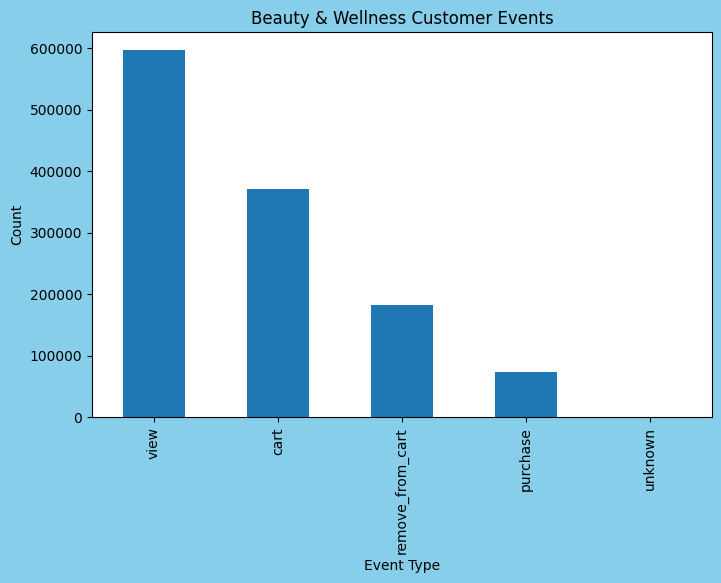

In [24]:
# Set up the figure dimensions and background color
plt.figure(figsize=(8, 5), facecolor="skyblue")

# Count occurrences of each event type and plot as a bar chart
final_df['event_type'].value_counts().plot(kind='bar')

# Set chart title
plt.title("Beauty & Wellness Customer Events")

# Label the X-axis
plt.xlabel("Event Type")

# Label the Y-axis
plt.ylabel("Count")

# Render the plot
plt.show()

##**Event Type Distribution**

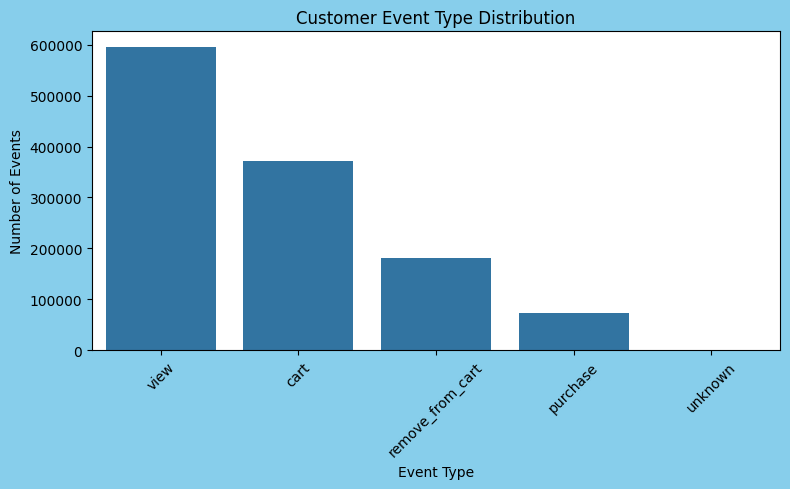

In [25]:
# Initialize figure size and background style
plt.figure(figsize=(8, 5), facecolor="skyblue")

# Generate a count plot sorted from highest to lowest occurrences
sns.countplot(
    data=final_df,
    x='event_type',
    order=final_df['event_type'].value_counts().index
)

# Set main title for the distribution map
plt.title('Customer Event Type Distribution')

# Apply axis labels
plt.xlabel('Event Type')
plt.ylabel('Number of Events')

# Rotate categories on X-axis for readability
plt.xticks(rotation=45)

# Adjust padding to prevent label cropping
plt.tight_layout()

# Render the visual plot
plt.show()

##**Top 10 Popular Brands**

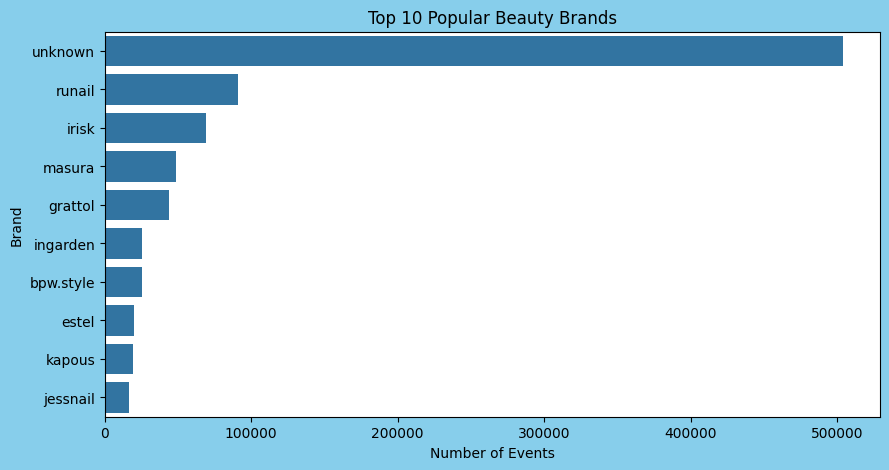

In [26]:
# Initialize figure layout with custom background color
plt.figure(figsize=(10, 5), facecolor="skyblue")

# Get top 10 brands by transaction volume
top_brands = final_df['brand'].value_counts().head(10)

# Generate a horizontal bar plot for the popular brands
sns.barplot(x=top_brands.values, y=top_brands.index)

# Configure chart title and axis labels
plt.title('Top 10 Popular Beauty Brands')
plt.xlabel('Number of Events')
plt.ylabel('Brand')

# Display the final bar chart
plt.show()

##**Product Price Distribution**

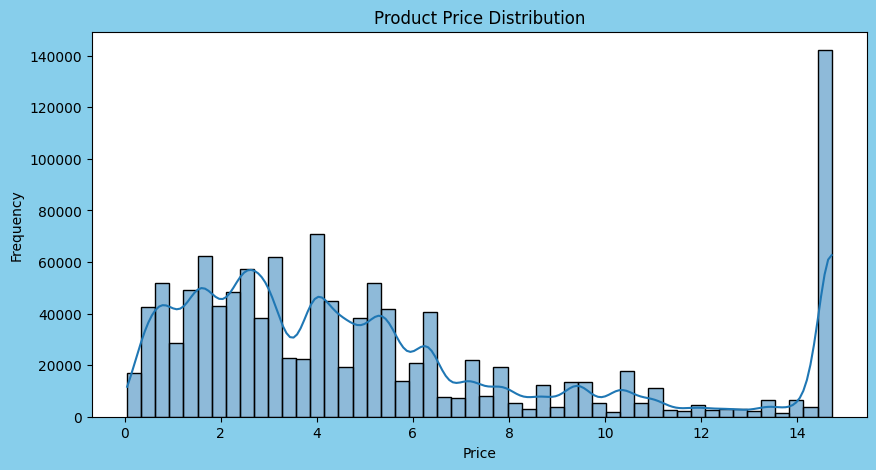

In [27]:
# Configure the figure layout dimensions
plt.figure(figsize=(10, 5), facecolor="skyblue")

# Create a histogram with a kernel density estimate curve overlay
sns.histplot(final_df['price'], bins=50, kde=True)

# Add visual boundaries, title, and labels
plt.title('Product Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

# Render the density chart
plt.show()

##**Price Outlier Detection**

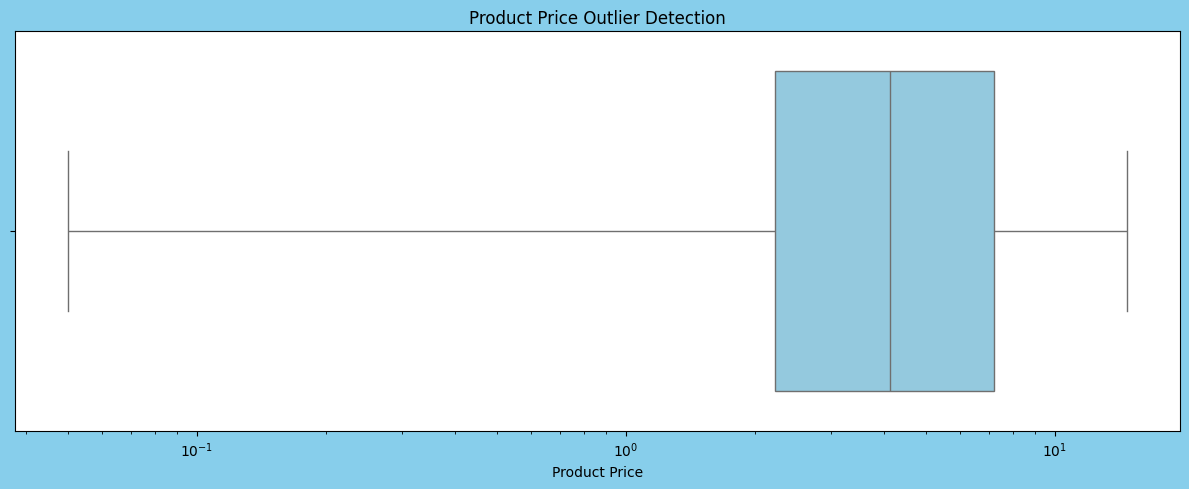

In [28]:
# Set custom canvas sizing and canvas color
plt.figure(figsize=(12, 5), facecolor="skyblue")

# Create a boxplot of prices to identify outlier ranges
sns.boxplot(x=final_df['price'], color='skyblue')

# Apply chart metadata descriptions
plt.title('Product Price Outlier Detection')
plt.xlabel('Product Price')

# Apply log scale for highly skewed price metrics
plt.xscale('log')

# Automatically fit margins
plt.tight_layout()

# Render the completed boxplot
plt.show()

##**Save Final Cleaned Dataset**

In [29]:
# Export cleaned dataframe back to a local CSV file
final_df.to_csv('Beauty_Wellness_Cleaned_Dataset.csv', index=False)

# Output confirmation message to console
print("Final Cleaned Dataset Saved Successfully!")

Final Cleaned Dataset Saved Successfully!
